# 03 - Chọn công cụ cho băng tải (bài đo quan trọng nhất)

**Đo cái gì?** Operator nói một câu (có thể bị nhiễu do nhận dạng giọng nói); model phải chọn đúng 1 trong 11 công cụ của hệ thống (hoặc không chọn gì nếu yêu cầu không liên quan) và điền đúng tham số. 156 câu, sinh bằng seed cố định.

**Vì sao cần?** Đây chính là việc SLM làm trong hệ thống. Điểm cao ở notebook 01 chưa chắc làm tốt việc này.

**Cách đọc biểu đồ:** Một câu chỉ tính đúng khi chọn đúng công cụ VÀ mọi tham số đúng hoàn toàn. Bài đo thêm: (1) cùng câu hỏi nhưng đưa cho model 3, 6 hay 11 công cụ; (2) câu sạch và câu nhiễu giọng nói.

**Giới hạn (để chuẩn bị phản biện):** Bộ câu hỏi do nhóm tự viết (xem `tool_cases.py`) nên không phải chuẩn quốc tế; vì vậy có thêm notebook 04 (BFCL) làm đối chứng. Tham số văn bản tự do như `reason` chỉ cần có, không chấm nội dung.

**Định dạng prompt:** đo 2 kiểu. (1) JSON tự chế: tool nằm trong tin nhắn user, model phải trả đúng khuôn `action_type/tool_call` (có grammar). (2) Native: tool đưa qua tham số `tools`, model dùng chat template của chính nó. Kiểm chứng tay: Qwen3-1.7B Q8 được 0/12 với (1) nhưng 10/12 với (2), nên khi chọn model hãy nhìn `native_acc_all`. Câu trả lời thô lưu ở `results/raw/`.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd
import tool_cases as T
cases = T.make_cases()
core = [c for c in cases if c['core']]   # câu chỉ dùng 3 công cụ gốc + câu ngoài phạm vi
print(len(cases), 'câu;', len(core), 'câu dùng cho bài so sánh 3/6/11 công cụ')

156 câu; 60 câu dùng cho bài so sánh 3/6/11 công cụ


Ví dụ một câu và đúng những gì model nhận được:

In [2]:
c = cases[5]
print('Operator nói:', c['context']['user_prompt'])
print('Đáp án đúng:', c['tool'], c['args'])
print(T.messages(c, T.TOOL_SETS[3])[1]['content'][:400], '...')

Operator nói: okay show me heat level for last 5 minutes
Đáp án đúng: query_blackbox_logs {'target_metric': 'temperature', 'lookback_minutes': 5}
{"fsm_state":"RUNNING","telemetry":{"belt_speed_rpm":30,"motor_current_ma":1200,"motor_temp_c":40.0},"user_prompt":"okay show me heat level for last 5 minutes","available_tools":[{"type":"function","function":{"name":"query_blackbox_logs","description":"Look up sensor/incident HISTORY from the database. Use for questions about when something happened in the past.","parameters":{"type":"object","pr ...


In [3]:
import json
RAW_DIR = st.RESULTS_DIR / "raw"

def run(srv, case_list, size):
    """Định dạng CŨ: tool nằm trong JSON của tin nhắn user, khuôn trả lời tự chế + grammar."""
    names = T.TOOL_SETS[size]
    grammar = T.grammar_for(names)                 # ép model chỉ trả JSON đúng khuôn
    out = []
    for c in case_list:
        text = srv.ask(T.messages(c, names), grammar)["text"]
        out.append((c, T.score(c, text), text))
    return out

def run_native(srv, case_list, size):
    """Định dạng CHUẨN: tool đưa qua tham số `tools`, model dùng chat template của chính nó."""
    names = T.TOOL_SETS[size]
    out = []
    for c in case_list:
        msgs, tools = T.native_request(c, names)
        try:
            a = srv.ask(msgs, tools=tools)
        except Exception as e:      # vd. xLAM: chat template của model không chạy được trên llama.cpp -> HTTP 500
            s = {"valid": False, "tool_ok": False, "args_ok": False, "over_trigger": False, "ok": False, "error": True}
            out.append((c, s, {"error": str(e)[:200]}))
            continue
        out.append((c, {**T.score_native(c, a), "error": False}, {"text": a["text"], "tool_calls": a["tool_calls"]}))
    return out

def rate(rows, key="ok"):
    return float(np.mean([s[key] for _, s, _ in rows]))

def save_raw(srv, name, rows):
    """Lưu câu trả lời thô để kiểm tra khi điểm bất thường (vd. model không bao giờ gọi tool)."""
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with open(RAW_DIR / f"{name}__{srv.cfg['id']}.jsonl", "w", encoding="utf-8") as f:
        for c, s, raw in rows:
            f.write(json.dumps({"id": c["id"], "want": c["tool"], "args": c["args"], "ok": s["ok"], "raw": raw},
                               ensure_ascii=False) + "\n")

def measure(srv):
    r3, r6, r11 = run(srv, core, 3), run(srv, core, 6), run(srv, cases, 11)
    n11 = run_native(srv, cases, 11)
    save_raw(srv, "tool_calling_json", r11)
    save_raw(srv, "tool_calling_native", n11)
    return {
        # định dạng cũ (JSON tự chế)
        "acc_3": rate(r3), "acc_6": rate(r6),
        "acc_11": rate([x for x in r11 if x[0]["core"]]),       # cùng câu hỏi như r3, r6
        "acc_all": rate(r11),                                      # cả 156 câu, đủ 11 công cụ
        "acc_clean": rate([x for x in r11 if not x[0]["noisy"]]),
        "acc_noisy": rate([x for x in r11 if x[0]["noisy"]]),
        "over_trigger": rate([x for x in r11 if x[0]["tool"] is None], "over_trigger"),
        "valid_json": rate(r11, "valid"),
        # định dạng chuẩn (native tool calling) - con số nên dùng để chọn model
        "native_acc_all": rate(n11),
        "native_acc_clean": rate([x for x in n11 if not x[0]["noisy"]]),
        "native_acc_noisy": rate([x for x in n11 if x[0]["noisy"]]),
        "native_over_trigger": rate([x for x in n11 if x[0]["tool"] is None], "over_trigger"),
        "native_error_rate": rate(n11, "error"),   # >0: chat template của model không chạy được trên llama.cpp
    }

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

In [4]:
st.run_all("tool_calling", measure, require=("native_acc_all",))   # kết quả cũ thiếu native -> đo lại

[đã có] SmolLM2-135M-Instruct (F16)
[đã có] Qwen2.5-0.5B-Instruct (F16)
[đã có] Qwen3-0.6B (F16)
[đã có] Gemma-3-1B-it (F16)
[đã có] Arch-Agent-1.5B (F16)
[đã có] xLAM-2-1B-fc-r (F16)
[đã có] Qwen3-1.7B (F16)
[đã có] Arch-Agent-3B (F16)
[đã có] Arch-Agent-1.5B (Q8)
[đã có] xLAM-2-1B-fc-r (Q8)
[đã có] Qwen3-1.7B (Q8)
[đã có] Arch-Agent-3B (Q8)
[đã có] Phi-4-mini-instruct (Q8)
[đã có] Arch-Agent-3B (Q4)
[đã có] Phi-4-mini-instruct (Q4)
[đã có] Qwen2.5-0.5B-Instruct (Q8)
[đã có] Qwen2.5-0.5B-Instruct (Q4)
[đã có] Qwen3-0.6B (Q8)
[đã có] Qwen3-0.6B (Q4)
[đã có] Gemma-3-1B-it (Q4)
[đã có] Arch-Agent-1.5B (Q4)
[đã có] xLAM-2-1B-fc-r (Q4)
[đã có] Qwen3-1.7B (Q4)


## Biểu đồ 1 - Model nào chọn đúng công cụ nhất?

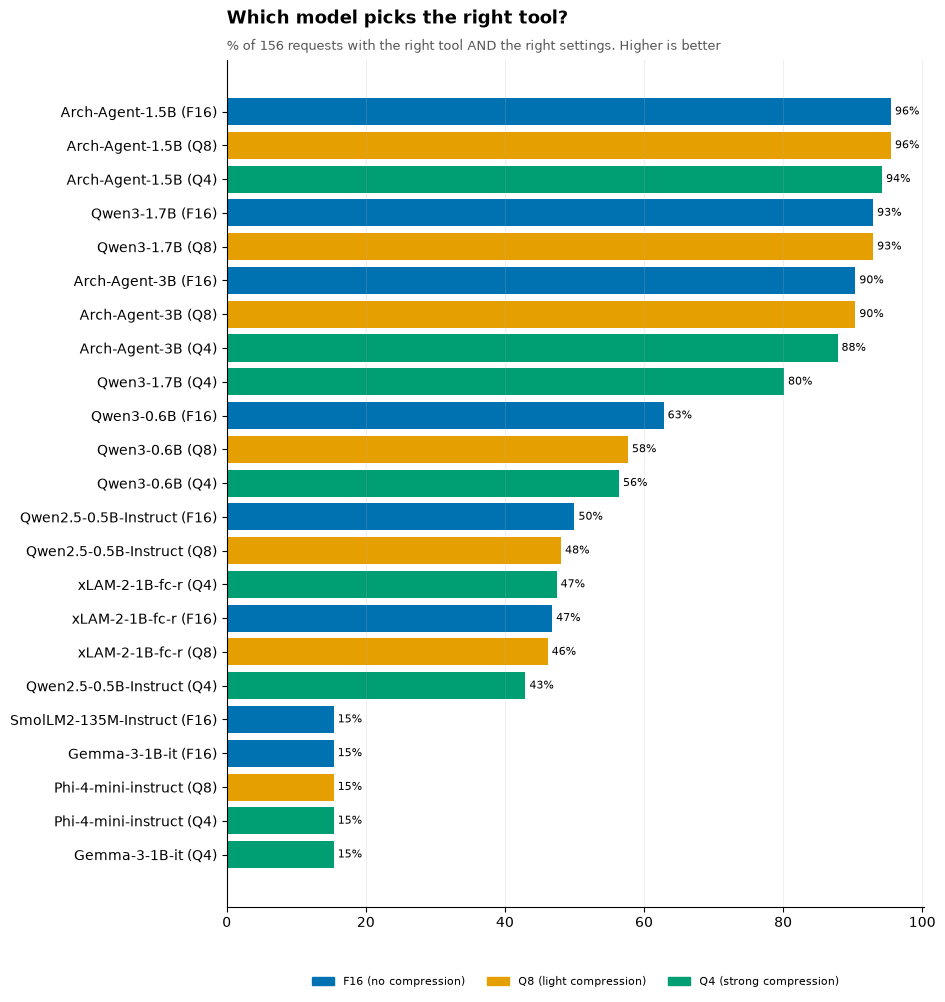

In [11]:
df = st.load("tool_calling")
st.bar_chart(df, "native_acc_all", "Which model picks the right tool?",
             "% of 156 requests with the right tool AND the right settings. Higher is better", name="03_tool_accuracy")

## Biểu đồ 1b - Định dạng prompt ảnh hưởng thế nào?

Cùng 156 câu, so sánh định dạng JSON tự chế (cũ) với tool-calling chuẩn của model (native). Nếu cột native cao hơn nhiều thì điểm thấp ở định dạng cũ là do prompt, không phải do model kém.

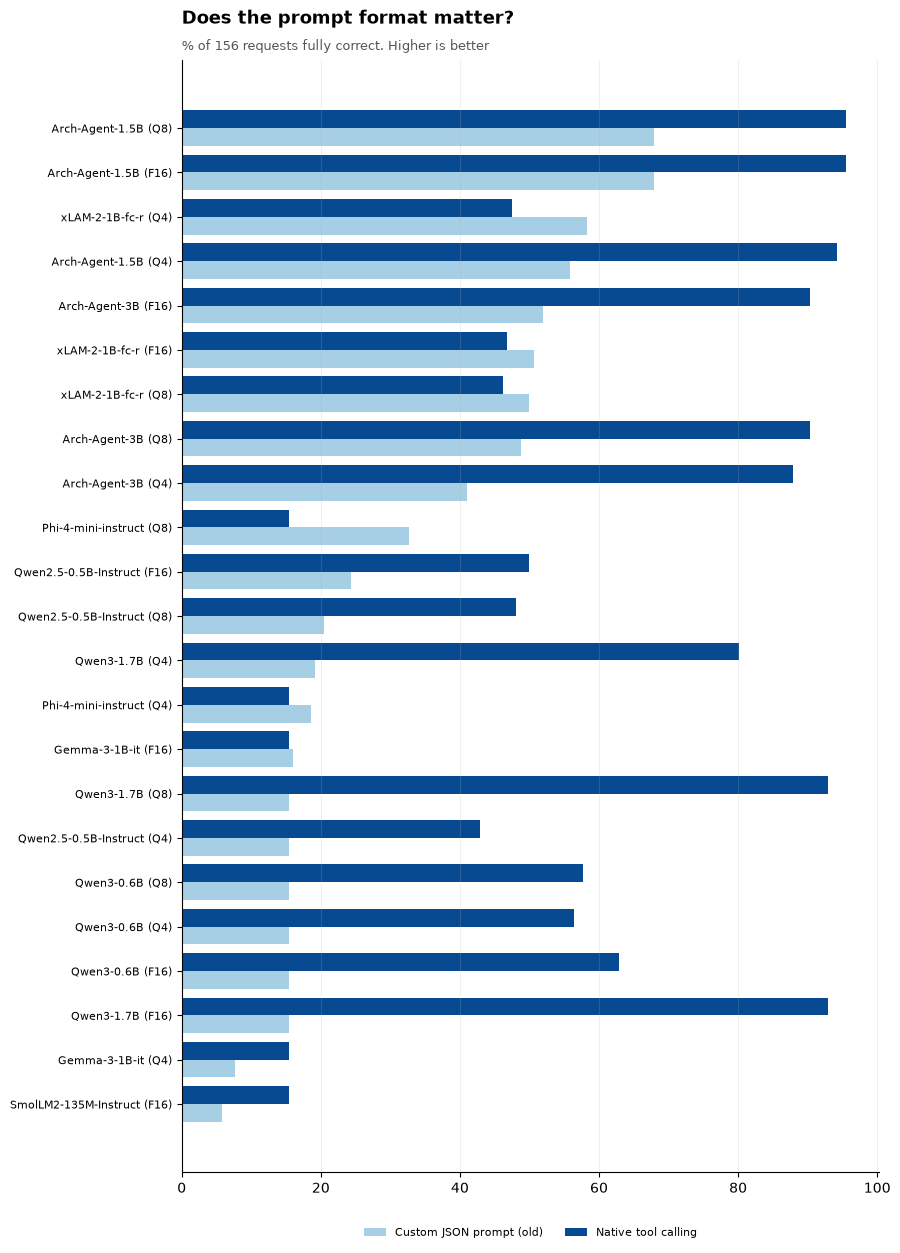

In [6]:
st.grouped_bars(df, {"acc_all": "Custom JSON prompt (old)", "native_acc_all": "Native tool calling"},
                "Does the prompt format matter?", "% of 156 requests fully correct. Higher is better",
                name="03_format")

## Biểu đồ 2 - Nhiều công cụ hơn có làm model bị rối không?

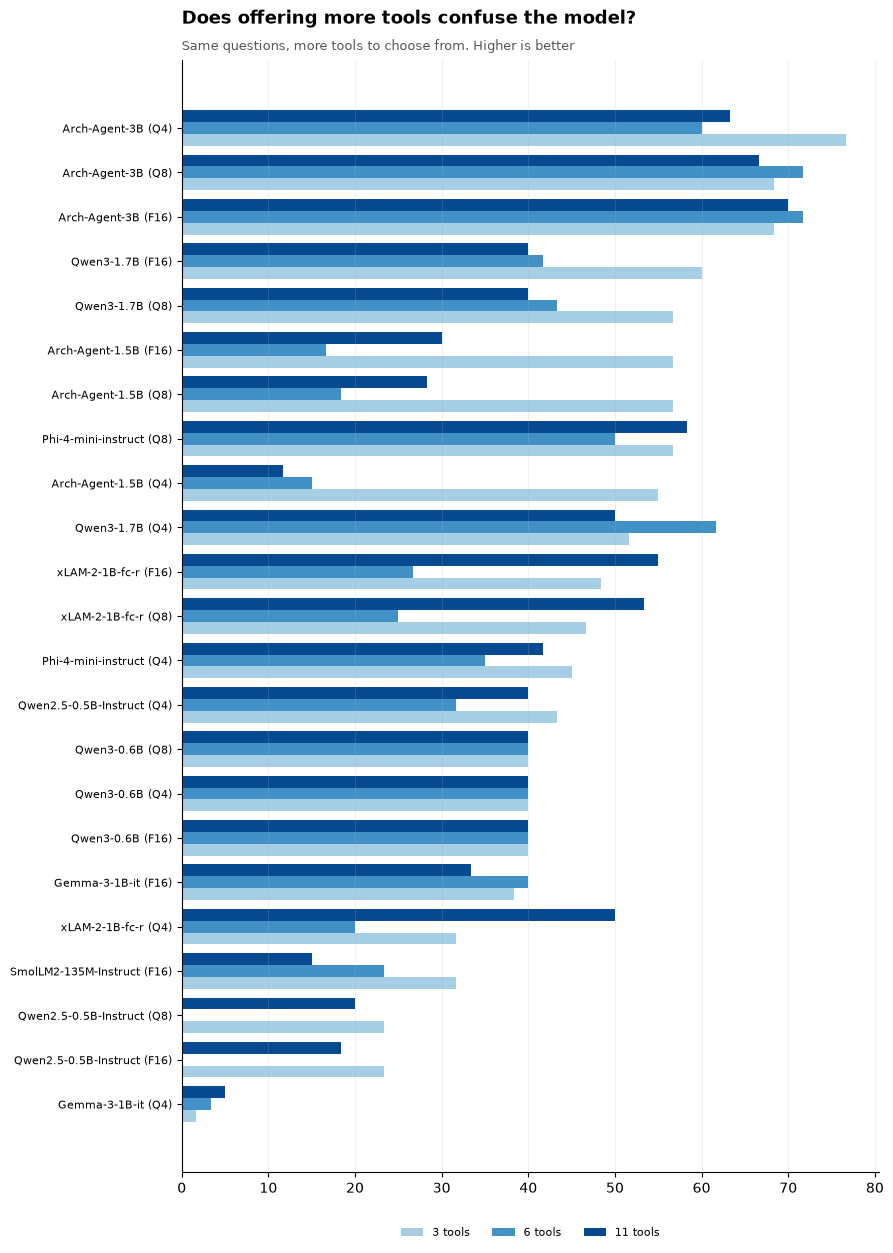

In [7]:
st.grouped_bars(df, {"acc_3": "3 tools", "acc_6": "6 tools", "acc_11": "11 tools"},
                "Does offering more tools confuse the model?",
                "Same questions, more tools to choose from. Higher is better", name="03_more_tools")

## Biểu đồ 3 - Nhiễu giọng nói có làm hỏng kết quả không?

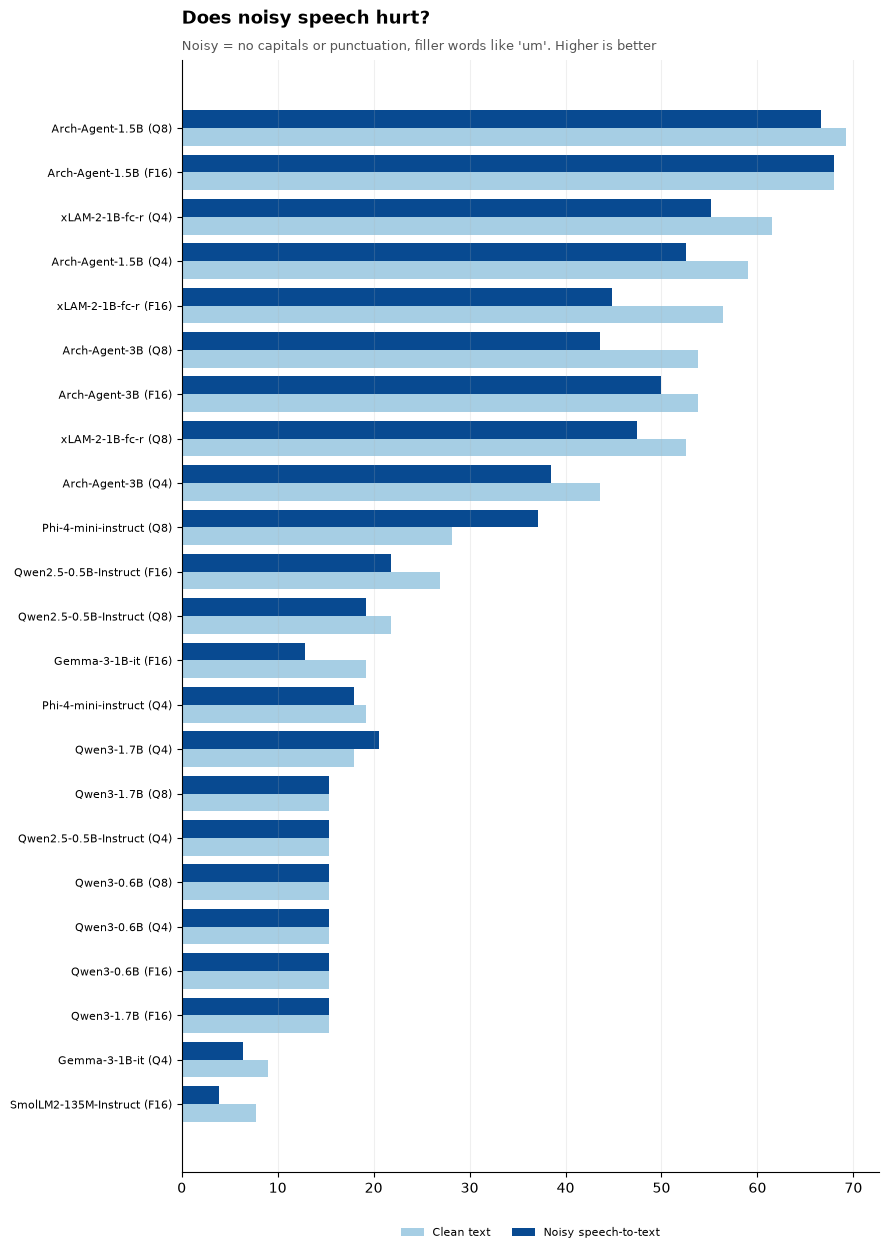

In [8]:
st.grouped_bars(df, {"acc_clean": "Clean text", "acc_noisy": "Noisy speech-to-text"},
                "Does noisy speech hurt?", "Noisy = no capitals or punctuation, filler words like 'um'. Higher is better",
                name="03_noise")

## Biểu đồ 4 - Model nào hay gọi công cụ khi không cần?

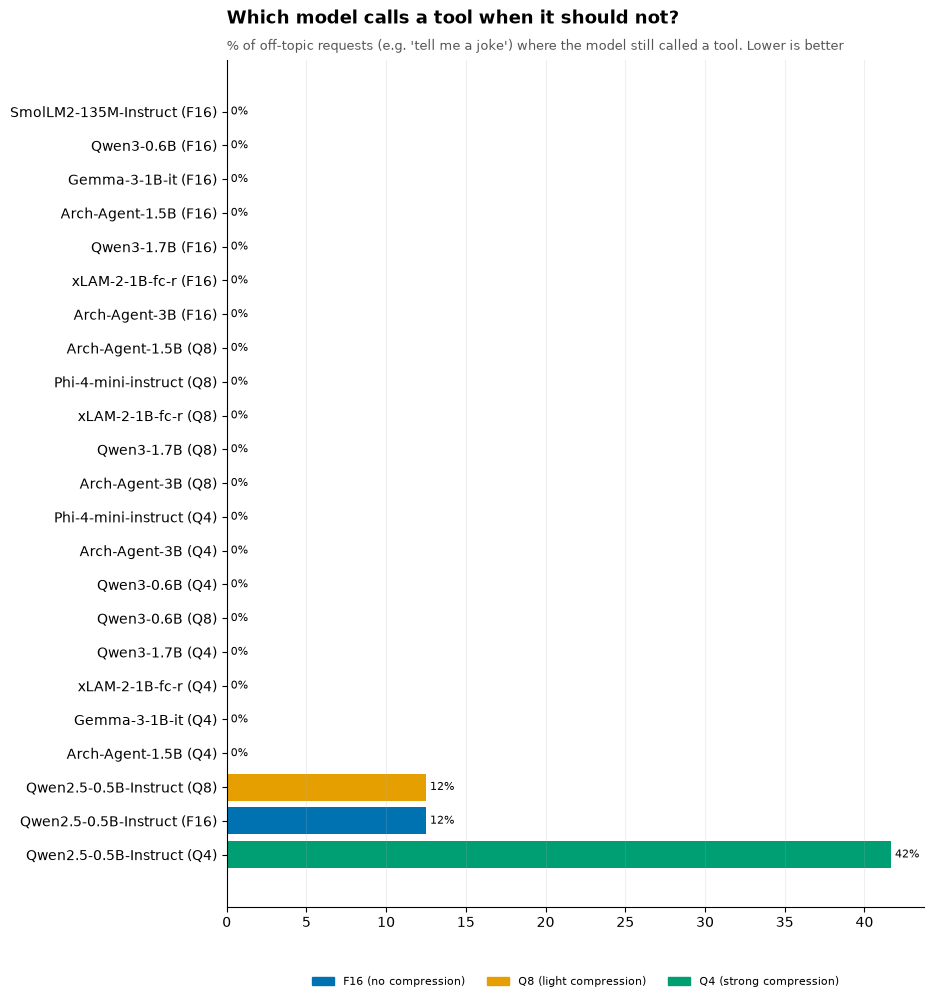

In [12]:
st.bar_chart(df, "native_over_trigger", "Which model calls a tool when it should not?",
             "% of off-topic requests (e.g. 'tell me a joke') where the model still called a tool. Lower is better",
             lower_is_better=True, name="03_over_trigger")